<a href="https://colab.research.google.com/github/AlexJ2410/Machine-Learning/blob/main/Sklearn_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

# Synthetic dataset of animals
data = {
    'Animal': [
        'Dog', 'Cat', 'Human', 'Platypus', 'Whale', 'Kangaroo', 'Bat', 'Elephant', 'Opossum', 'Koala',
        'Boa Constrictor', 'Iguana', 'Alligator', 'Garter Snake', 'Chameleon', 'Gecko', 'Python', 'Komodo Dragon',
        'Eagle', 'Penguin', 'Robin', 'Ostrich', 'Hawk', 'Owl', 'Pelican',
        'Salmon', 'Goldfish', 'Shark', 'Tuna', 'Clownfish'
    ],
    'Class': [
        'Mammal', 'Mammal', 'Mammal', 'Mammal', 'Mammal', 'Mammal', 'Mammal', 'Mammal', 'Mammal', 'Mammal',
        'Reptile', 'Reptile', 'Reptile', 'Reptile', 'Reptile', 'Reptile', 'Reptile', 'Reptile',
        'Bird', 'Bird', 'Bird', 'Bird', 'Bird', 'Bird', 'Bird',
        'Fish', 'Fish', 'Fish', 'Fish', 'Fish'
    ],
    'Body_Temp': [
        38.5, 38.0, 37.0, 32.0, 36.0, 36.5, 37.5, 36.0, 35.5, 36.0,
        25.0, 28.0, 26.0, 22.0, 24.0, 25.0, 23.0, 27.0,
        41.0, 39.0, 40.5, 39.5, 41.5, 40.0, 40.0,
        15.0, 18.0, 16.0, 20.0, 19.0
    ],
    'Gives_Birth': [1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
    'Has_Feathers': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
    'Breathes_Air': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
}

df = pd.DataFrame(data)
display(df)

,Animal,Class,Body_Temp,Gives_Birth,Has_Feathers,Breathes_Air
0,Dog,Mammal,38.5,1,0,1
1,Cat,Mammal,38.0,1,0,1
2,Human,Mammal,37.0,1,0,1
3,Platypus,Mammal,32.0,0,0,1
4,Whale,Mammal,36.0,1,0,1
5,Kangaroo,Mammal,36.5,1,0,1
6,Bat,Mammal,37.5,1,0,1
7,Elephant,Mammal,36.0,1,0,1
8,Opossum,Mammal,35.5,1,0,1
9,Koala,Mammal,36.0,1,0,1


In [ ]:
def shannon_entropy(x):
  if len(x) == 0:
    return 0
  probs = x.value_counts(normalize=True)
  return -sum(p * np.log2(p) for p in probs if p>0)

def calc_info_gain(df, split_col, threshold, target_col='Class'):
  # Split into right and left branches
  if df[split_col].dtype in [np.float64, np.int64]:
    left_split = df[df[split_col] <= threshold]
    right_split = df[df[split_col] > threshold]
  else:
    left_split = df[df[split_col] == threshold]
    right_split = df[df[split_col] != threshold]

  parent_entropy = shannon_entropy(df[target_col])

  n = len(df)
  n_l, n_r = len(left_split), len(right_split)

  if n_l == 0 or n_r == 0:
    return 0

  weighted_entropy = (n_l)/n * shannon_entropy(left_split[target_col]) + (n_r)/n * shannon_entropy(right_split[target_col])
  return parent_entropy - weighted_entropy

def best_cont_split(df, col, target_col='Class'):
  # Find midpoints between sorted unique values in the column
  sorted_values = sorted(df[col].unique())
  candidate_thresholds = [(sorted_values[i] + sorted_values[i+1])/2.0 for i in range(len(sorted_values)-1)]

  best_gain = -1
  best_threshold = None

  for t in candidate_thresholds:
    gain = calc_info_gain(df, col, t, target_col)
    if gain > best_gain:
      best_gain = gain
      best_threshold = t

  return best_threshold, best_gain

best_temp_threshold, max_temp_gain = best_cont_split(df, 'Body_Temp')
print(f"Best Body_Temp split threshold: {best_temp_threshold:.2f} °C with Information Gain: {max_temp_gain:.4f}")

Best Body_Temp split threshold: 30.00 °C with Information Gain: 0.9871


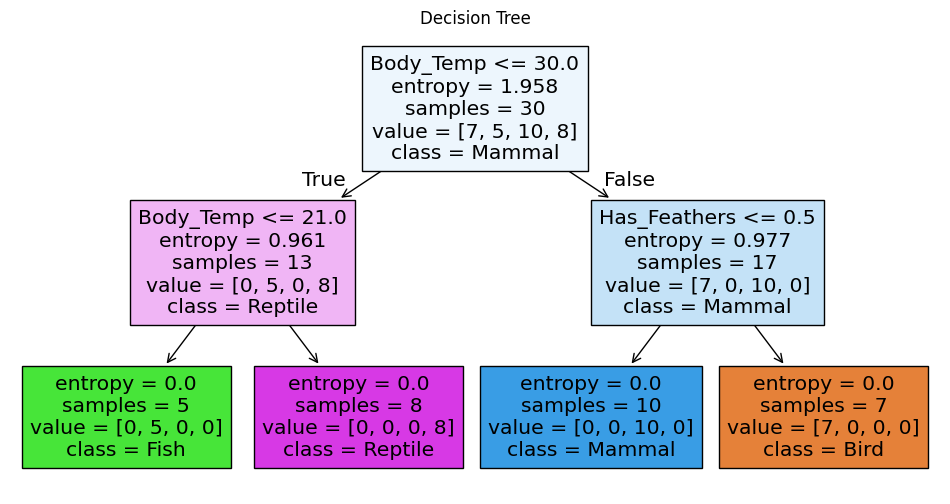

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import matplotlib.pyplot as plt

X = df[['Body_Temp', 'Gives_Birth', 'Has_Feathers', 'Breathes_Air']].copy()
y = df['Class']

clf = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=42)
clf.fit(X, y)
plt.figure(figsize=(12,6))
tree.plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True)
plt.title("Decision Tree")
plt.show()

In [ ]:
sk_root_threshold = clf.tree_.threshold[0]

manual_threshold, manual_gain = best_cont_split(df, 'Body_Temp')

print(f"Manual best Body_Temp threshold: {manual_threshold:.2f} °C")
print(f"Scikit-learn root Body_Temp threshold: {sk_root_threshold:.2f} °C")

# Assert they match perfectly
assert manual_threshold == sk_root_threshold, "Thresholds do not match!"
print("Assertion Passed: Manual split matches scikit-learn's root split perfectly!")

Manual best Body_Temp threshold: 30.00 °C
Scikit-learn root Body_Temp threshold: 30.00 °C
Assertion Passed: Manual split matches scikit-learn's root split perfectly!


In [ ]:
from sklearn.model_selection import LeaveOneOut
from sklearn.tree import DecisionTreeClassifier, export_text
import pandas as pd

LOO = LeaveOneOut()
X_restricted = df[['Body_Temp', 'Gives_Birth']].copy()
y = df['Class']

In [ ]:
# Print the decision tree rules specifically for the Platypus and Penguin LOO folds
for train_idx, test_idx in LOO.split(X_restricted):
    animal_name = df.iloc[test_idx]['Animal'].values[0]
    if animal_name in ['Platypus', 'Penguin']:
        X_train, X_test = X_restricted.iloc[train_idx], X_restricted.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        clf_loo = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=42)
        clf_loo.fit(X_train, y_train)

        print(f"\n=== Decision Tree Rules for {animal_name}'s Fold ===")
        tree_rules = export_text(clf_loo, feature_names=list(X_restricted.columns))
        print(tree_rules)


=== Decision Tree Rules for Platypus's Fold ===
|--- Body_Temp <= 31.75
|   |--- Body_Temp <= 21.00
|   |   |--- class: Fish
|   |--- Body_Temp >  21.00
|   |   |--- class: Reptile
|--- Body_Temp >  31.75
|   |--- Gives_Birth <= 0.50
|   |   |--- class: Bird
|   |--- Gives_Birth >  0.50
|   |   |--- class: Mammal


=== Decision Tree Rules for Penguin's Fold ===
|--- Body_Temp <= 30.00
|   |--- Body_Temp <= 21.00
|   |   |--- class: Fish
|   |--- Body_Temp >  21.00
|   |   |--- class: Reptile
|--- Body_Temp >  30.00
|   |--- Body_Temp <= 39.00
|   |   |--- class: Mammal
|   |--- Body_Temp >  39.00
|   |   |--- class: Bird



In [ ]:
from sklearn.model_selection import LeaveOneOut

# We restrict features to 'Body_Temp' and 'Gives_Birth' to test model boundaries
X_restricted = df[['Body_Temp', 'Gives_Birth']].copy()

LOO = LeaveOneOut()
correct_predictions = 0
misclassified_animals = []

for train_idx, test_idx in LOO.split(X_restricted):
    X_train, X_test = X_restricted.iloc[train_idx], X_restricted.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Restricting depth to 2 to see where the simple boundary rules break
    clf_loo = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=42)
    clf_loo.fit(X_train, y_train)

    pred = clf_loo.predict(X_test)[0]
    actual = y_test.values[0]
    animal_name = df.iloc[test_idx]['Animal'].values[0]

    if pred == actual:
        correct_predictions += 1
    else:
        misclassified_animals.append({
            'Animal': animal_name,
            'Actual Class': actual,
            'Predicted Class': pred,
            'Body_Temp': X_test.iloc[0]['Body_Temp'],
            'Gives_Birth': X_test.iloc[0]['Gives_Birth']
        })

accuracy = correct_predictions / len(X_restricted)
print(f"LOOCV (Restricted Feature Space) Accuracy: {accuracy * 100:.2f}%")
print("\n--- Misclassified Animals (Boundary Failures) ---")
display(pd.DataFrame(misclassified_animals))

LOOCV (Restricted Feature Space) Accuracy: 93.33%

--- Misclassified Animals (Boundary Failures) ---


,Animal,Actual Class,Predicted Class,Body_Temp,Gives_Birth
0,Platypus,Mammal,Bird,32.0,0.0
1,Penguin,Bird,Mammal,39.0,0.0


In [ ]:
# Sensitivity analysis: evaluating LOOCV accuracy across max_depth values from 1 to 4
results = {}
for depth in [1, 2, 3, 4]:
    correct = 0
    for train_idx, test_idx in LOO.split(X_restricted):
        X_train, X_test = X_restricted.iloc[train_idx], X_restricted.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        clf_sens = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42)
        clf_sens.fit(X_train, y_train)
        pred = clf_sens.predict(X_test)[0]
        if pred == y_test.values[0]:
            correct += 1
    results[depth] = correct / len(X_restricted)

for depth, acc in results.items():
    print(f"Max Depth {depth} LOOCV Accuracy: {acc * 100:.2f}%")

Max Depth 1 LOOCV Accuracy: 60.00%
Max Depth 2 LOOCV Accuracy: 93.33%
Max Depth 3 LOOCV Accuracy: 93.33%
Max Depth 4 LOOCV Accuracy: 93.33%


### 5. Detailed Model Validation & Limitations

#### Why the LOOCV Failures Occurred
* **Platypus:** In the Platypus fold, the tree splits on `Body_Temp <= 31.75` (the midpoint between the warmest reptile at 28.0°C and the coldest remaining mammal at 35.5°C) to separate cold-blooded from warm-blooded animals. Because the Platypus has a body temperature of 32.0°C, it goes to the warm-blooded branch (`Body_Temp > 31.75`). In this branch, the tree then splits on `Gives_Birth <= 0.5`. Since the Platypus does not give live birth (`Gives_Birth = 0`), it is classified as a **Bird** (which is the only class of warm-blooded egg-layers in the remaining training set).
* **Penguin:** In the Penguin fold, the tree splits warm-blooded animals (`Body_Temp > 30.0`) on `Body_Temp <= 39.0` rather than birth method. This threshold represents the midpoint between the warmest mammal (Dog at 38.5°C) and the coolest other bird (Ostrich at 39.5°C). Because the Penguin's temperature is exactly 39.0°C and scikit-learn splits using "less than or equal to", it is funneled into the mammalian branch despite being an egg-layer.

#### Sensitivity & Bounds of the Model
* **Feature Limitations:** With features restricted to just `Body_Temp` and `Gives_Birth`, the model is highly sensitive to taxonomic outliers.
* **Depth Sensitivity:** At `max_depth=1`, the model is underfitted, achieving only a 60.00% LOOCV accuracy. Accuracy increases and stabilizes at 93.33% for depths 2, 3, and 4 on this dataset.